# Aula 12 — Usando o Q-BASIC: Wigner, emaranhamento e sistemas abertos

Nas aulas anteriores construímos, passo a passo, as peças de um simulador quântico. Elas viraram a
biblioteca `qbasic`. Nesta aula usamos a versão completa da biblioteca para explorar fenômenos que
seriam trabalhosos de programar do zero:

1. objetos quânticos densos e esparsos;
2. a função de Wigner de estados coerentes e de um "gato de Schrödinger";
3. o colapso e o renascimento das oscilações de Rabi (modelo de Jaynes-Cummings);
4. o emaranhamento entre o átomo e a cavidade;
5. sistemas abertos: perda de fótons e decoerência (equação mestra de Lindblad).

Para rodar fora do Colab: `pip install "Q-BASIC[plot]"`.

In [1]:
import matplotlib.pyplot as plt
import numpy as np

import qbasic as qb

print("Q-BASIC", qb.__version__)

Q-BASIC 0.1.0


## 1. Objetos quânticos

Tudo é um `ObjQuantico`: kets, bras, operadores e matrizes densidade. Cada um pode ser **denso** (NumPy)
ou **esparso** (SciPy), e os dois formatos se misturam nas contas. No Jupyter, os objetos aparecem como
matrizes em LaTeX.

In [2]:
a = qb.destruicao(4)
a

ObjQuantico: tipo=operador, dim=4, shape=(4, 4), formato=denso
[[0.     1.     0.     0.    ]
 [0.     0.     1.4142 0.    ]
 [0.     0.     0.     1.7321]
 [0.     0.     0.     0.    ]]

In [3]:
a_esparso = qb.destruicao(1000, sparsa=True)
print(a_esparso.formato, a_esparso.shape, 'elementos não nulos:', a_esparso.dados.nnz)

esparso (1000, 1000) elementos não nulos: 999


As convenções são: `A * B` é o produto matricial, `A @ B` (ou `qb.tensor(A, B)`) é o produto tensorial,
e `A + 2` significa $A + 2I$. Sistemas compostos guardam a dimensão de cada parte em `dims`:

In [4]:
psi = qb.tensor(qb.fock(3, 1), qb.ket("0"))
print(psi.dims)
print(qb.comutador(qb.destruicao(5), qb.criacao(5)).full().real.diagonal())  # [a, a†] = 1 (exceto o último nível)

[[3, 2], [1, 1]]
[ 1.  1.  1.  1. -4.]


## 2. Função de Wigner

A função de Wigner $W(x, p)$ representa um estado no espaço de fase. Para estados "clássicos", como o
estado coerente $|\alpha\rangle$, ela é uma gaussiana positiva. Valores **negativos** indicam um estado
genuinamente quântico.

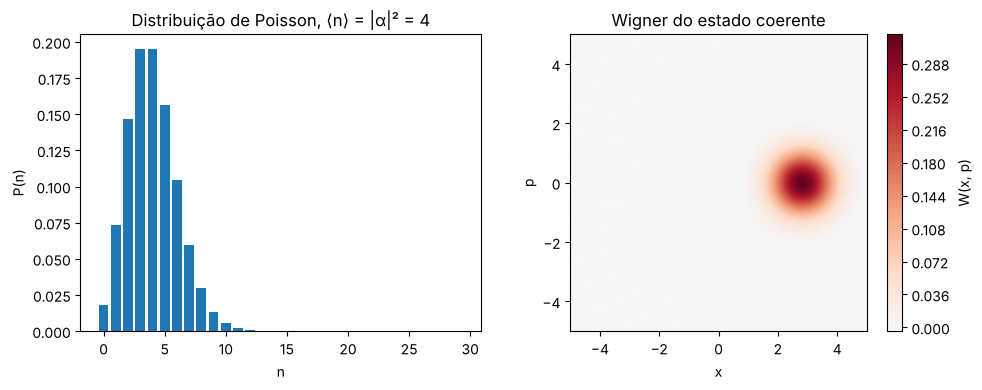

In [5]:
N = 30
alfa = 2.0
coerente = qb.coerente(N, alfa)

fig, eixos = plt.subplots(1, 2, figsize=(10, 4))
qb.plotar_fock(coerente, ax=eixos[0])
eixos[0].set_title("Distribuição de Poisson, ⟨n⟩ = |α|² = 4")
qb.plotar_wigner(coerente, ax=eixos[1])
eixos[1].set_title("Wigner do estado coerente")
plt.tight_layout()

Um **gato de Schrödinger** é a superposição de dois estados coerentes "macroscopicamente" diferentes,
$|\alpha\rangle + |-\alpha\rangle$. As franjas de interferência entre as duas gaussianas têm valores
negativos:

mínimo de W: -0.236  (negativo: estado não clássico)


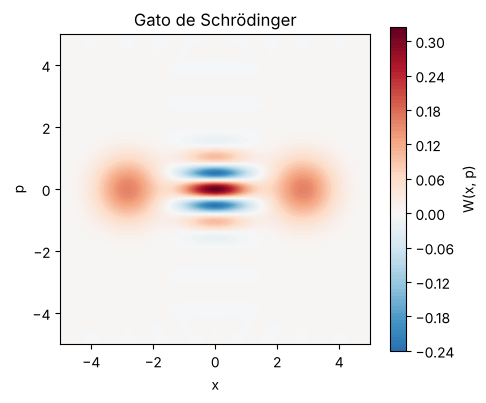

In [6]:
gato = (qb.coerente(N, alfa) + qb.coerente(N, -alfa)).normalizar()
x = np.linspace(-5, 5, 201)
W = qb.wigner(gato, x, x)
print(f"mínimo de W: {W.min():.3f}  (negativo: estado não clássico)")
qb.plotar_wigner(gato, x, x)
plt.title("Gato de Schrödinger");

## 3. Colapso e renascimento (Jaynes-Cummings)

Um átomo de dois níveis (fundamental $|0\rangle$, excitado $|1\rangle$) interage com uma cavidade:

$$H = g\,(a^\dagger \sigma_- + a\,\sigma_+).$$

Com a cavidade num estado coerente, cada número de fótons $n$ oscila com uma frequência diferente,
$2g\sqrt{n+1}$. As oscilações se desfazem (colapso) e voltam a entrar em fase em $t \approx 2\pi|\alpha|/g$
(renascimento). O espaço tem dimensão 80; usamos matrizes esparsas.

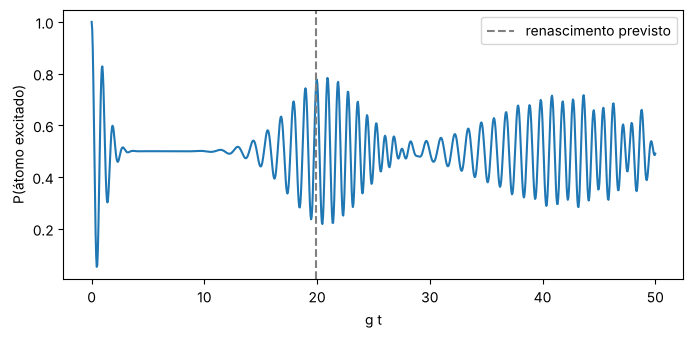

In [7]:
N = 40
g = 1.0
alfa = np.sqrt(10)

a = qb.tensor(qb.destruicao(N, sparsa=True), qb.identidade(2, sparsa=True))
sm = qb.tensor(qb.identidade(N, sparsa=True), qb.destruicao(2, sparsa=True))
H = g * (a.dag() * sm + a * sm.dag())

psi0 = qb.tensor(qb.coerente(N, alfa), qb.ket("1"))  # átomo excitado
tempos = np.linspace(0, 50, 1000)
resultado = qb.resolver_schrodinger(H, psi0, tempos, observaveis=[sm.dag() * sm])

plt.figure(figsize=(8, 3.5))
plt.plot(tempos, resultado.valores_esperados[0])
plt.axvline(2 * np.pi * alfa / g, color="gray", linestyle="--", label="renascimento previsto")
plt.xlabel("g t")
plt.ylabel("P(átomo excitado)")
plt.legend();

## 4. Emaranhamento entre o átomo e a cavidade

Durante a evolução, o átomo e a cavidade ficam emaranhados. Uma medida disso é a **entropia de von
Neumann** do átomo sozinho, obtida com o **traço parcial** sobre a cavidade: zero para um estado
produto, até 1 bit para o emaranhamento máximo de um qubit.

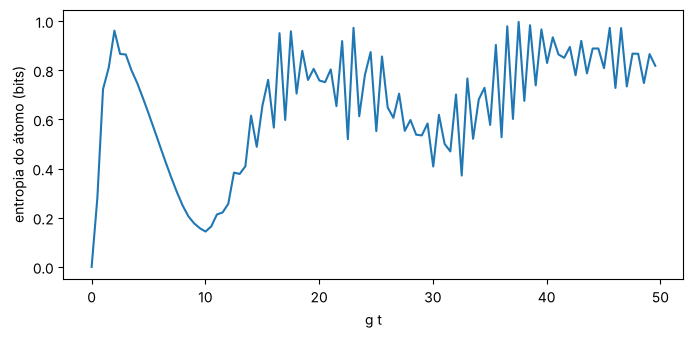

In [8]:
estados = resultado.estados[::10]
entropia = [qb.entropia_von_neumann(qb.traco_parcial(psi, 1)) for psi in estados]

plt.figure(figsize=(8, 3.5))
plt.plot(tempos[::10], entropia)
plt.xlabel("g t")
plt.ylabel("entropia do átomo (bits)");

## 5. Sistemas abertos: equação mestra de Lindblad

Uma cavidade real perde fótons. A evolução da matriz densidade $\rho$ segue a equação de Lindblad

$$\frac{d\rho}{dt} = -i[H, \rho] + \kappa\left(a\rho a^\dagger - \tfrac12\{a^\dagger a, \rho\}\right),$$

que no `qbasic` é resolvida por `resolver_lindblad`, passando o operador de colapso $\sqrt{\kappa}\,a$.
Para um estado coerente, o número médio de fótons decai como $|\alpha|^2 e^{-\kappa t}$:

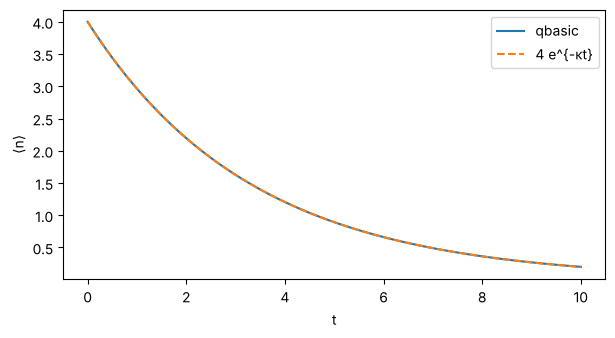

In [9]:
N = 30
kappa = 0.3
a = qb.destruicao(N)
tempos = np.linspace(0, 10, 101)

res = qb.resolver_lindblad(qb.numero(N), qb.coerente(N, 2.0), tempos, [np.sqrt(kappa) * a], [qb.numero(N)])

plt.figure(figsize=(7, 3.5))
plt.plot(tempos, res.valores_esperados[0], label="qbasic")
plt.plot(tempos, 4 * np.exp(-kappa * tempos), "--", label="4 e^{-κt}")
plt.xlabel("t")
plt.ylabel("⟨n⟩")
plt.legend();

A perda de fótons é ainda mais destrutiva para a superposição: as franjas de interferência do gato
(a "quanticidade") somem muito antes de os fótons acabarem. Isso é a **decoerência**.

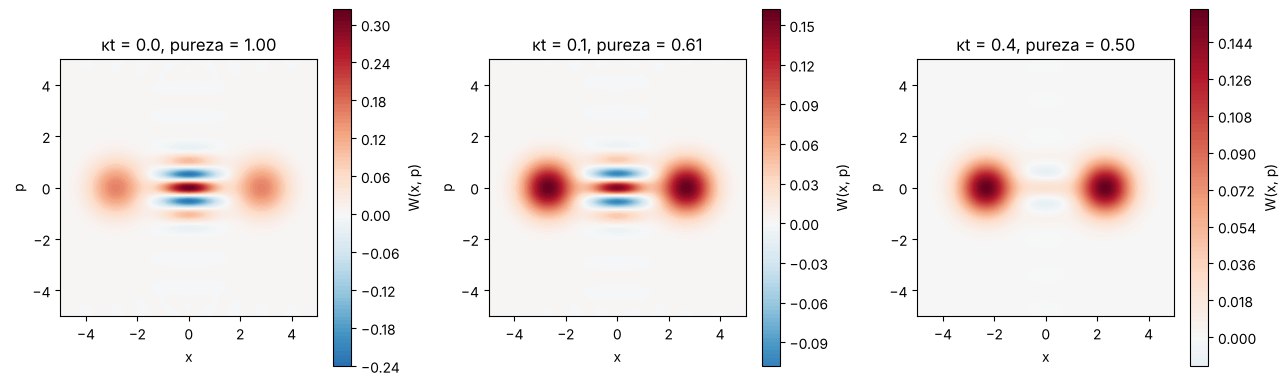

In [10]:
res = qb.resolver_lindblad(0 * qb.numero(N), gato, [0, 0.1, 0.4], [np.sqrt(1.0) * a])

fig, eixos = plt.subplots(1, 3, figsize=(13, 4))
for eixo, t, rho in zip(eixos, res.tempos, res.estados):
    qb.plotar_wigner(rho, x, x, ax=eixo)
    eixo.set_title(f"κt = {t:.1f}, pureza = {qb.pureza(rho):.2f}")
plt.tight_layout()

## Para continuar

- A documentação completa, com a referência de todas as funções, está no site do Q-BASIC.
- Os tutoriais de **computação quântica** usam as portas lógicas (`qb.hadamard`, `qb.cnot`...), medidas
  (`qb.amostrar`) e a esfera de Bloch (`qb.esfera_bloch`).